In [12]:
# Step 1: Import libraries
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model




In [13]:
# Step 2: Load MNIST dataset
print("Loading MNIST dataset...")
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


Loading MNIST dataset...


In [14]:

# Step 3: Normalize and flatten images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)


In [15]:

# Step 4: Use only digit 3 as normal data
train_normal = x_train[y_train == 3][:3000]
test_normal = x_test[y_test == 3][:100]
test_anomaly = x_test[y_test == 7][:100]



In [16]:
# Step 5: Build the Autoencoder
input_img = Input(shape=(784,))

# Encoder: compresses the input
encoded = Dense(64, activation="relu")(input_img)
encoded = Dense(32, activation="relu")(encoded)

# Decoder: reconstructs the input
decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(784, activation="sigmoid")(decoded)

autoencoder = Model(input_img, decoded)



In [17]:
# Step 6: Compile the model
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()



Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 784)]             0         
                                                                 
 dense_8 (Dense)             (None, 64)                50240     
                                                                 
 dense_9 (Dense)             (None, 32)                2080      
                                                                 
 dense_10 (Dense)            (None, 64)                2112      
                                                                 
 dense_11 (Dense)            (None, 784)               50960     
                                                                 
Total params: 105,392
Trainable params: 105,392
Non-trainable params: 0
_________________________________________________________________


In [18]:
# Step 7: Train the Autoencoder
print("\nTraining Autoencoder...")

autoencoder.fit(
    train_normal, train_normal,
    epochs=5,
    batch_size=128,
    shuffle=True,
    validation_data=(test_normal, test_normal),
    verbose=1
)



Training Autoencoder...
Epoch 1/5
24/24 [==============================] - 0s 4ms/step - loss: 0.1600 - val_loss: 0.0659
Epoch 2/5
24/24 [==============================] - 0s 3ms/step - loss: 0.0623 - val_loss: 0.0564
Epoch 3/5
24/24 [==============================] - 0s 3ms/step - loss: 0.0579 - val_loss: 0.0537
Epoch 4/5
24/24 [==============================] - 0s 2ms/step - loss: 0.0529 - val_loss: 0.0493
Epoch 5/5
24/24 [==============================] - 0s 2ms/step - loss: 0.0479 - val_loss: 0.0452


In [19]:

# Step 8: Prepare normal and anomalous test data
test_data = np.concatenate([test_normal, test_anomaly])
test_labels = np.array([0] * len(test_normal) + [1] * len(test_anomaly))


In [20]:

# Step 9: Calculate reconstruction error
reconstructions = autoencoder.predict(test_data, verbose=0)
mse = np.mean((test_data - reconstructions) ** 2, axis=1)



In [21]:
# Step 10: Set anomaly threshold
threshold = np.mean(mse[test_labels == 0]) + 2 * np.std(mse[test_labels == 0])

print("\nAnomaly Threshold:", round(threshold, 4))
print("Total test samples:", len(test_data))
print("Samples detected as anomalies:", np.sum(mse > threshold))




Anomaly Threshold: 0.0718
Total test samples: 200
Samples detected as anomalies: 52


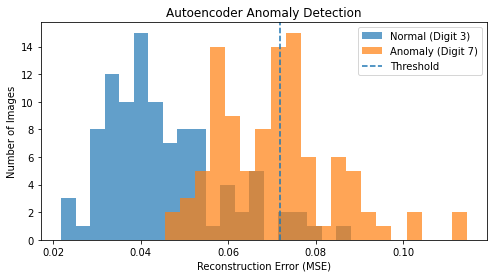

In [22]:
# Step 11: Plot reconstruction errors
plt.figure(figsize=(8, 4))
plt.hist(mse[test_labels == 0], bins=20, alpha=0.7, label="Normal (Digit 3)")
plt.hist(mse[test_labels == 1], bins=20, alpha=0.7, label="Anomaly (Digit 7)")
plt.axvline(threshold, linestyle="--", label="Threshold")
plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Number of Images")
plt.title("Autoencoder Anomaly Detection")
plt.legend()
plt.show()


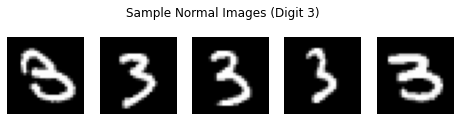


Anomaly detection completed!


In [23]:

# Step 12: Display example images
plt.figure(figsize=(8, 2))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(test_data[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Sample Normal Images (Digit 3)")
plt.show()

print("\nAnomaly detection completed!")